Здесь будем проектировать модель классификации для начала.

In [61]:
from pathlib import Path
import os

from tqdm import tqdm

import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, DataLoader
from torch import nn

In [32]:
dir_path=Path().cwd().parent 

data_dir_path=dir_path/'data/severstal-steel-defect-detection'
assert data_dir_path.exists()

images_train_dir=data_dir_path/'train_images'
images_val_dir=data_dir_path/'test_images'

In [83]:
random_state=4223

In [3]:
train_df=pd.read_csv(data_dir_path/'train.csv')
train_df.head()

,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,0007a71bf.jpg,3,18661 28 18863 82 19091 110 19347 110 19603 11...
2,000a4bcdd.jpg,1,37607 3 37858 8 38108 14 38359 20 38610 25 388...
3,000f6bf48.jpg,4,131973 1 132228 4 132483 6 132738 8 132993 11 ...
4,0014fce06.jpg,3,229501 11 229741 33 229981 55 230221 77 230468...


In [4]:
all_images=sorted(os.listdir(images_train_dir))
images_df = pd.DataFrame({
    "ImageId": sorted(all_images)
})

images_df["has_defect"] = images_df["ImageId"].isin(train_df['ImageId']).astype(int)


images_df=images_df.merge(
    train_df,
    on='ImageId',
    how='left'
)

images_df['ClassId']=images_df['ClassId'].fillna(0)
images_df['EncodedPixels']=images_df['EncodedPixels'].fillna('0')

images_df.head()

,ImageId,has_defect,ClassId,EncodedPixels
0,0002cc93b.jpg,1,1.0,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,00031f466.jpg,0,0.0,0
2,000418bfc.jpg,0,0.0,0
3,000789191.jpg,0,0.0,0
4,0007a71bf.jpg,1,3.0,18661 28 18863 82 19091 110 19347 110 19603 11...


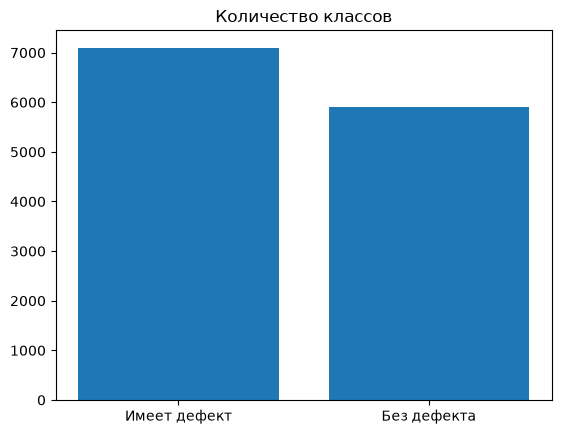

In [11]:
target_counts=images_df.has_defect.value_counts()

plt.title('Количество классов')
plt.bar(['Имеет дефект', 'Без дефекта'], target_counts)
plt.show()

In [84]:
df_train, df_val = train_test_split(images_df, test_size=0.2, stratify=images_df.ClassId, random_state=random_state)

In [85]:
print(f'Train size: {df_train.shape}')
print(f'Val size: {df_val.shape}')

Train size: (10397, 4)
Val size: (2600, 4)


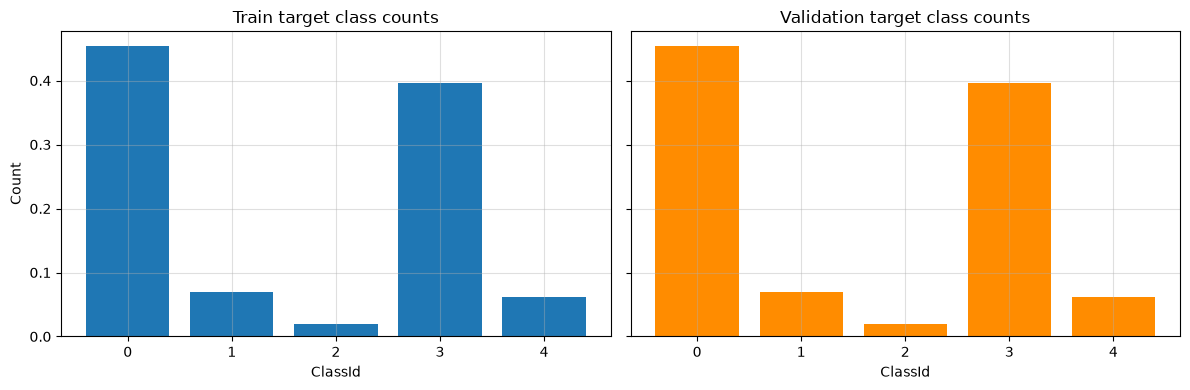

In [95]:
train_target_counts = df_train.ClassId.value_counts(normalize=True).sort_index()
val_target_counts = df_val.ClassId.value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].bar(train_target_counts.index, train_target_counts)
axes[0].set_title('Train target class counts')
axes[0].set_xlabel('ClassId')
axes[0].set_ylabel('Count')
axes[0].grid(alpha=0.4)

axes[1].bar(val_target_counts.index, val_target_counts, color='darkorange')
axes[1].set_title('Validation target class counts')
axes[1].set_xlabel('ClassId')
axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.show()

In [73]:
class ClassificationDataset(Dataset):
    def __init__(self, data_df, images_dir):
        self.data_df=data_df
        self.images_dir=images_dir

    def __len__(self):
        return len(self.data_df)

    def __getitem__(self, index):
        row=self.data_df.iloc[index]

        img_path=self.images_dir/row.ImageId

        img=cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        img=torch.tensor(img) / 255.0
        img=img.unsqueeze(0)
        return img, torch.tensor(row.has_defect.item())

In [74]:
train_dataset=ClassificationDataset(df_train, images_train_dir)
val_dataset=ClassificationDataset(df_val, images_train_dir)


train_dataloader=DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    drop_last=True,

)

val_dataloader=DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    
)

In [ ]:
class CnnModel(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()

        self.features=nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.RelU(),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AvgPool2d(1)
        )

        self.fcn=nn.Sequential(
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        return self.fcn(
            self.features(x)
        )

In [77]:
for img, labels in tqdm(train_dataloader):
    pass
    break

  0%|          | 0/324 [00:00<?, ?it/s]


In [78]:
img.shape

torch.Size([32, 1, 256, 1600])